# Augmented GNN comparison

Cached post-fit validation results only. The GNN was fit on positions, trajectories, and graph structure; p-ratio is evaluated only after fitting.

In [2]:
from pathlib import Path
import json
import sys
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / 'notebooks').is_dir():
    raise RuntimeError('Run from the repository root.')
sys.path.insert(0, str(ROOT / 'src'))
from lss.plotting import apply_editorial_style
apply_editorial_style('light')
EVAL = ROOT / 'notebooks/results/lj_mp2_scope20/downstream/evaluation'
required = ['postfit_seed_aggregate.csv', 'postfit_per_network.csv', 'added_edge_count_summary.csv', 'evaluation.json']
missing = [name for name in required if not (EVAL / name).is_file()]
if missing:
    raise FileNotFoundError(f'Run downstream post-fit evaluation first; missing: {missing}')
aggregate = pd.read_csv(EVAL / 'postfit_seed_aggregate.csv')
per_network = pd.read_csv(EVAL / 'postfit_per_network.csv')
edge_summary = pd.read_csv(EVAL / 'added_edge_count_summary.csv')
metadata = json.loads((EVAL / 'evaluation.json').read_text())
assert metadata['final_test_used'] is False
COLORS = {'base': '#4C78A8', 'random': '#F58518', 'latent': '#54A24B'}
LABELS = {'ljonly60': 'LJ-only AE (60 LJ)', 'shared3x20': 'Shared AE (20 each)'}

## GNN with and without added edges

Autonomous rollout on the same 20 held-out noisy-LJ networks. Lines show mean p-ratio R² across three seeds; shading is ±1 SD. At each horizon, both true and predicted p-ratios use the same boundary-strain fit over frames 0–horizon. The baseline is the LJ-only-scope base run (the matched shared-scope baseline differs by less than 0.00003 R²). The vertical axis is limited to 0–1; saved scores are unchanged.

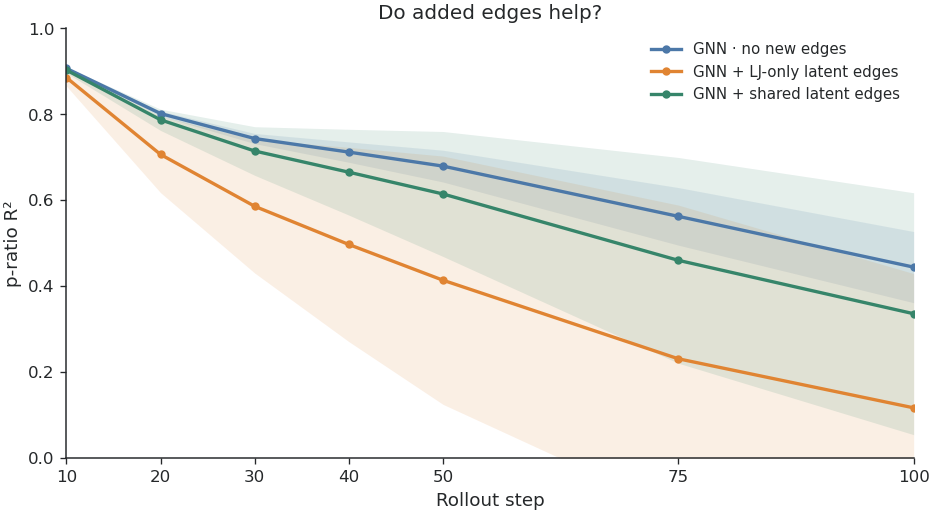

In [3]:
fig, ax = plt.subplots(figsize=(7.8, 4.3), constrained_layout=True)
comparisons = [
    ('ljonly60', 'base', 'GNN · no new edges', '#4C78A8'),
    ('ljonly60', 'latent', 'GNN + LJ-only latent edges', '#E08432'),
    ('shared3x20', 'latent', 'GNN + shared latent edges', '#36856A'),
]
for scope, arm, label, color in comparisons:
    values = aggregate.loc[aggregate.scope.eq(scope) & aggregate.arm.eq(arm)].sort_values('frame')
    assert values.frame.tolist() == [10, 20, 30, 40, 50, 75, 100]
    assert values.seeds.eq(3).all() and values.p_ratio_valid.eq(values.p_ratio_total).all()
    mean = values.postfit_p_ratio_r2_mean
    sd = values.postfit_p_ratio_r2_sd
    ax.plot(values.frame, mean, marker='o', ms=4, lw=2, color=color, label=label)
    ax.fill_between(values.frame, mean-sd, mean+sd, color=color, alpha=.13, linewidth=0)
ax.set(title='Do added edges help?', xlabel='Rollout step', ylabel='p-ratio R²',
       xlim=(10, 100), ylim=(0, 1), xticks=[10, 20, 30, 40, 50, 75, 100])
ax.legend(fontsize=9)
plt.show()


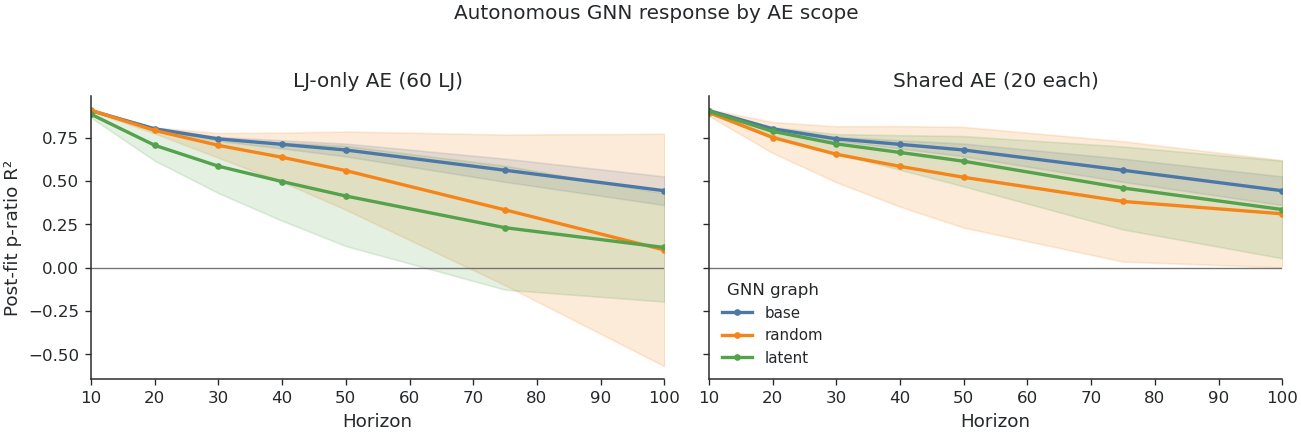

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (scope, group) in zip(axes, aggregate.groupby('scope', sort=False)):
    for arm in ['base', 'random', 'latent']:
        values = group[group.arm.eq(arm)].sort_values('frame')
        ax.plot(values.frame, values.postfit_p_ratio_r2_mean, marker='o', ms=3, color=COLORS[arm], label=arm)
        ax.fill_between(values.frame, values.postfit_p_ratio_r2_mean - values.postfit_p_ratio_r2_sd, values.postfit_p_ratio_r2_mean + values.postfit_p_ratio_r2_sd, color=COLORS[arm], alpha=.16)
    ax.axhline(0, color='.45', lw=.8)
    ax.set(title=LABELS[scope], xlabel='Horizon', xlim=(10, 100))
axes[0].set_ylabel('Post-fit p-ratio R²')
axes[1].legend(title='GNN graph')
fig.suptitle('Autonomous GNN response by AE scope', y=1.03)
fig.tight_layout()

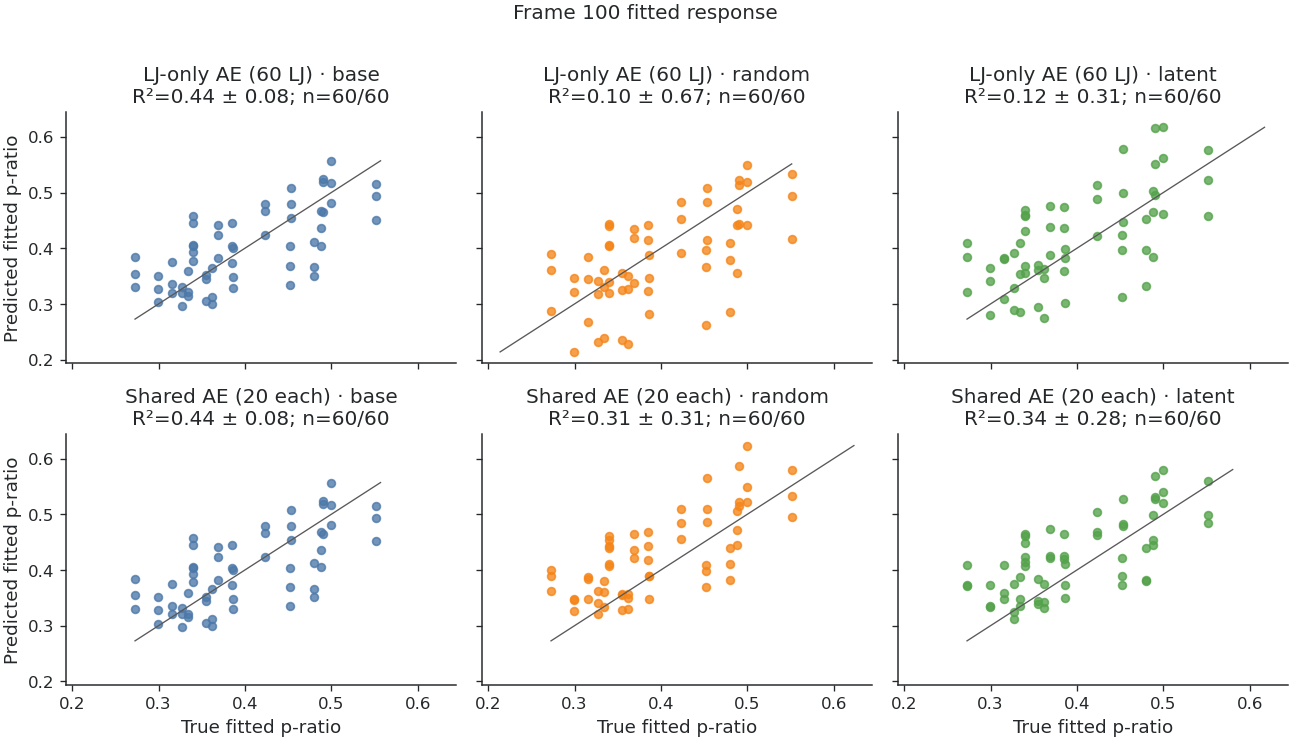

In [3]:
final = per_network[per_network.frame.eq(100)]
fig, axes = plt.subplots(2, 3, figsize=(11, 6.2), sharex=True, sharey=True)
for ax, ((scope, arm), group) in zip(axes.flat, final.groupby(['scope', 'arm'], sort=False)):
    valid = group[group.finite_pair]
    ax.scatter(valid.true_p_ratio, valid.pred_p_ratio, s=22, color=COLORS[arm], alpha=.78)
    lo = min(valid.true_p_ratio.min(), valid.pred_p_ratio.min()); hi = max(valid.true_p_ratio.max(), valid.pred_p_ratio.max())
    ax.plot([lo, hi], [lo, hi], color='.35', lw=.8)
    row = aggregate[(aggregate.scope == scope) & (aggregate.arm == arm) & (aggregate.frame == 100)].iloc[0]
    ax.set(title=f"{LABELS[scope]} · {arm}\nR²={row.postfit_p_ratio_r2_mean:.2f} ± {row.postfit_p_ratio_r2_sd:.2f}; n={int(row.p_ratio_valid)}/{int(row.p_ratio_total)}")
for ax in axes[-1]: ax.set_xlabel('True fitted p-ratio')
for ax in axes[:, 0]: ax.set_ylabel('Predicted fitted p-ratio')
fig.suptitle('Frame 100 fitted response', y=1.01)
fig.tight_layout()

Text(0.5, 1.02, 'Held-out LJ network 15: springs and learned edges')

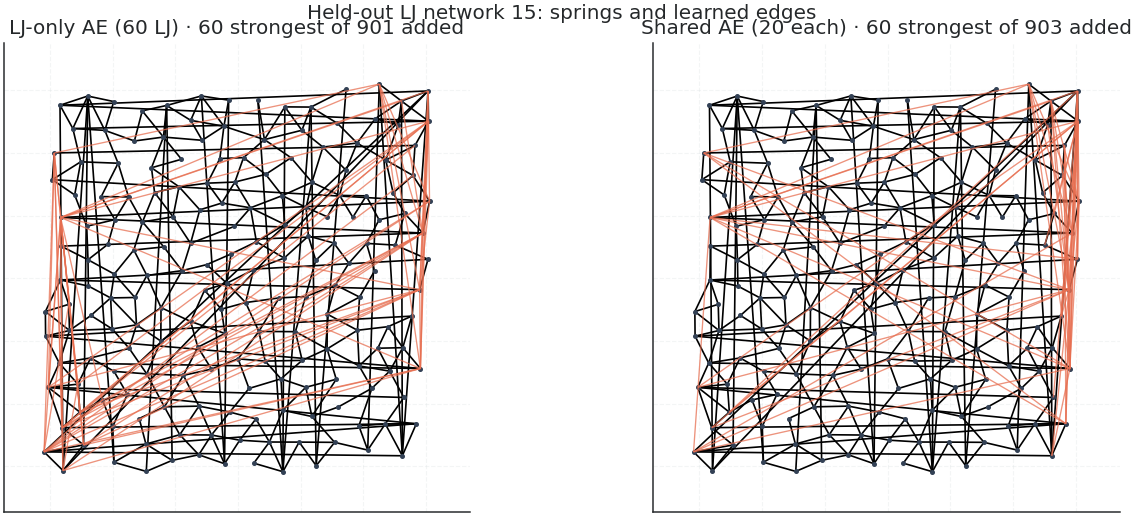

In [4]:
import networkx as nx
import numpy as np
import torch
from matplotlib.collections import LineCollection
from graph_utils import draw_graph

example = torch.load(EVAL / 'edge_example.pt', map_location='cpu', weights_only=True)
xy = example['node_xy_physical'].numpy()
spring_edges = example['spring_edges'].T.numpy()
network = nx.Graph()
network.add_nodes_from((i, {'pos': xy[i]}) for i in range(len(xy)))
network.add_edges_from(map(tuple, spring_edges))
fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.2), constrained_layout=True)
for ax, scope in zip(axes, ['ljonly60', 'shared3x20']):
    draw_graph(network, periodic_edges=True, node_color='#334155', node_size=4,
               show_labels=False, ax=ax, show=False)
    values = example['scope_edges'][scope]
    edges = values['added_edges'].T.numpy()
    strongest = values['scores'].argsort(descending=True)[:60].numpy()
    segments = np.stack((xy[edges[strongest, 0]], xy[edges[strongest, 1]]), axis=1)
    ax.add_collection(LineCollection(segments, colors='#e76f51', linewidths=.8, alpha=.75))
    ax.set(title=f"{LABELS[scope]} · 60 strongest of {len(edges)} added", aspect='equal')
fig.suptitle(f"Held-out LJ network {example['original_index']}: springs and learned edges", y=1.02)

The graph shows physical springs and the 60 strongest learned edges for one held-out network. The GNN also retains all graph-distance-two/three relations; every learned edge excludes those existing relations.

In [5]:
edge_summary.sort_values(['scope', 'arm']).style.format({'added_edges_mean': '{:.1f}', 'added_edges_sd': '{:.1f}'})

,scope,arm,seeds,networks,added_edges_mean,added_edges_sd,added_edges_min,added_edges_max
0,ljonly60,base,3,60,0.0,0.0,0,0
1,ljonly60,latent,3,60,739.8,164.6,461,968
2,ljonly60,random,3,60,739.8,164.6,461,968
3,shared3x20,base,3,60,0.0,0.0,0,0
4,shared3x20,latent,3,60,740.9,165.3,459,968
5,shared3x20,random,3,60,740.9,165.3,459,968


The table reports unique undirected added edges per validation network, aggregated across seeds. The base graph carries zero added edges; random and latent arms use the same edge-count rule.